# Exam exercises


For the exam, please prepare 2 exercises from this list.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## Q2: Planetary positions

The distances of the planets from the Sun (technically, their semi-major axes) are:

In [2]:
a = np.array([0.39, 0.72, 1.00, 1.52, 5.20, 9.54, 19.22, 30.06, 39.48])

These are in units where the Earth-Sun distance is 1 (astronomical units).

The corresponding periods of their orbits (how long they take to go once around the Sun) are, in years

In [3]:
P = np.array([0.24, 0.62, 1.00, 1.88, 11.86, 29.46, 84.01, 164.8, 248.09])

Finally, the names of the planets corresponding to these are:

In [4]:
names = ["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", 
         "Uranus", "Neptune", "Pluto"]

(technically, pluto isn't a planet anymore, but we still love it :)

  * Plot as points, the periods vs. distances for each planet on a log-log plot.

  * Write the name of the planet next to the point for that planet on the plot

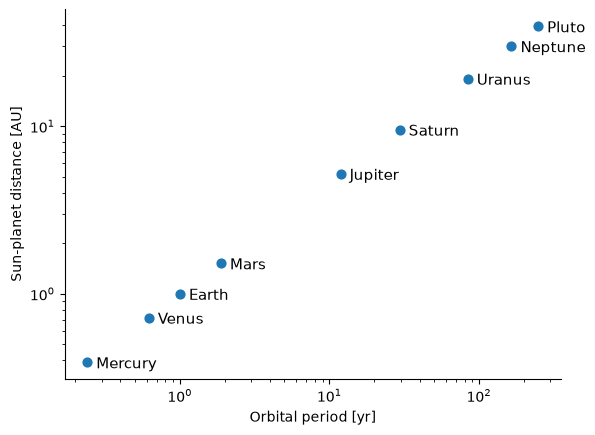

In [35]:
fig = plt.figure()
ax = fig.add_subplot(111)

ax.scatter(P, a, s=40)

for period, distance, name in zip(P,a,names):
    ax.text(period + 0.15*period, distance-0.08*distance, name, fontsize=11)

ax.loglog()
ax.set(xlabel='Orbital period [yr]', ylabel='Sun-planet distance [AU]')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

## Q4: Climate

Download the data file of global surface air temperature averages from here:
https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt
This data comes from: https://data.giss.nasa.gov/gistemp/graphs/

(Don't ask, of course you can download data straight from python! Packages `requests` and `urllib` can both do the job)

There are 3 columns here: the year, the temperature change, and a smoothed representation of the temperature change.  

  * Read in this data using `np.loadtxt()`.  
  * Plot as a line the smoothed representation of the temperature changes.  
  * Plot as points the temperature change (no smoothing).  Color the points blue if they are < 0 and color them red if they are >= 0
  
You might find the numpy `where()` function useful.

In [54]:
import requests

In [57]:
r = requests.get('https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt')
with open("temperatures.txt", mode="wb") as file:
    file.write(r.content)

file.close()

In [64]:
data = np.loadtxt("temperatures.txt")
data.shape

(137, 3)

[Text(0.5, 0, 'Year'), Text(0, 0.5, 'Temperature change [$^\\circ\\rm C$]')]

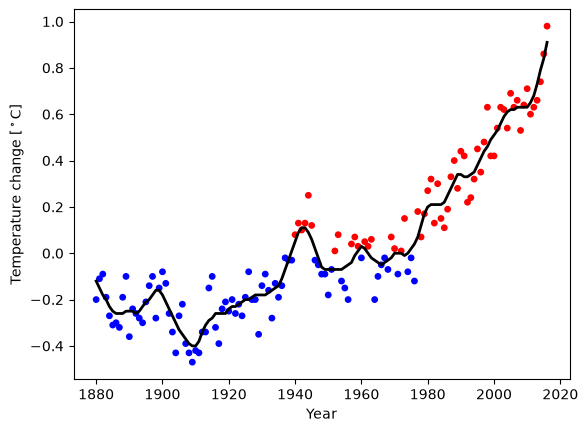

In [85]:
fig = plt.figure()
ax = fig.add_subplot(111)

ax.plot(data[:, 0], data[:, 2], c='black', lw=2)
ax.scatter(data[:, 0], data[:, 1], s=15, c=np.where(data[:, 1]<0, 'blue', 'red'), zorder=-1)

ax.set(xlabel='Year', ylabel='Temperature change [$^\\circ\\rm C$]')